**MWL community waiting lists, Oct 2025 to Sep 2026**




In [1]:
# Data: NHS England Community Health Services (CHS) SitRep, monthly files
# MWL = Mersey and West Lancashire Teaching Hospitals, provider code RBN

import pandas as pd, glob, re
import matplotlib.pyplot as plt

In [2]:
# each file has a tab for the total (Table 4) and one tab per wait band (4a to 4h)
bands = {"Table 4": "Total", "Table 4a": "0-1w", "Table 4b": "1-2w", "Table 4c": "2-4w",
         "Table 4d": "4-12w", "Table 4e": "12-18w", "Table 4f": "18-52w",
         "Table 4g": "52-104w", "Table 4h": "104w+"}

out = []
for f in glob.glob("*Community-health-services-waiting-lists*.xlsx"):
    # get the month from the file name, e.g. 2026-27-September
    month = re.search(r"\d{4}-\d{2}-[A-Za-z]+", f).group(0)

    for tab, band in bands.items():
        # first 4 rows are notes, real headers start on row 5
        df = pd.read_excel(f, sheet_name=tab, header=4)

        # I only need MWL and England (to compare)
        keep = df[(df["Organisation Code"] == "RBN") | (df["Organisation Name"] == "England")]

        # services are spread across columns, so turn them into rows
        long = keep.melt(id_vars=["Organisation Type", "Organisation Code", "Organisation Name"],
                         var_name="Service", value_name="Waiting")
        long["Band"] = band
        long["Month"] = month
        out.append(long)

data = pd.concat(out, ignore_index=True)

# blank cells mean the service isn't reported, not zero, so drop them
data["Waiting"] = pd.to_numeric(data["Waiting"], errors="coerce")
data = data.dropna(subset=["Waiting"])

data.to_csv("mwl_vs_england_chs.csv", index=False)
print(data["Month"].nunique(), "months loaded")

12 months loaded


In [3]:
# months sort alphabetically by default, so set the right order
order = ["2025-26-October", "2025-26-November", "2025-26-December", "2025-26-January",
         "2025-26-February", "2025-26-March", "2026-27-April", "2026-27-May", "2026-27-June",
         "2026-27-July", "2026-27-August", "2026-27-September"]
data["Month"] = pd.Categorical(data["Month"], categories=order, ordered=True)

mwl = data[data["Organisation Code"] == "RBN"]
eng = data[data["Organisation Name"] == "England"]

Month
2025-26-October      919.0
2025-26-November     902.0
2025-26-December     869.0
2025-26-January      898.0
2025-26-February     712.0
2025-26-March        782.0
2026-27-April        641.0
2026-27-May          680.0
2026-27-June         656.0
2026-27-July         715.0
2026-27-August         0.0
2026-27-September    534.0
Name: Waiting, dtype: float64


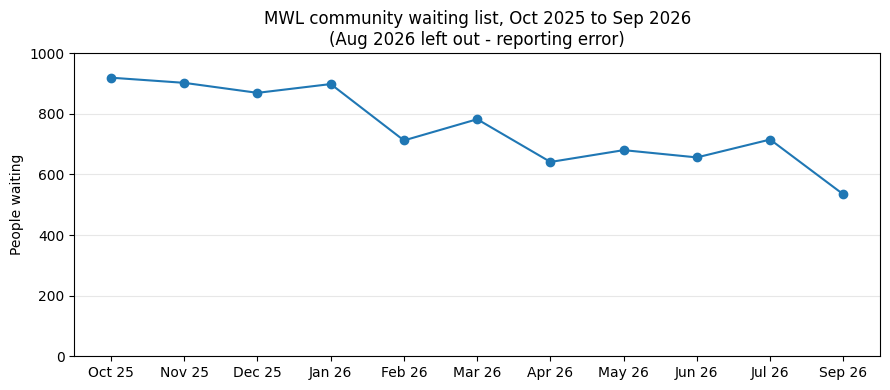

Oct 25: 919  Sep 26: 534  change: -42%


In [4]:
# MWL total waiting list each month
# waiting lists are a snapshot, so never add months together
trend = mwl[mwl["Band"] == "Total"].groupby("Month", observed=True)["Waiting"].sum()
print(trend)

# August came through as 0 for every service, even though ~300 children were
# waiting for paediatrics before and after - looks like a reporting error, so I left it out
trend = trend.drop("2026-27-August")

labels = ["Oct 25", "Nov 25", "Dec 25", "Jan 26", "Feb 26", "Mar 26",
          "Apr 26", "May 26", "Jun 26", "Jul 26", "Sep 26"]

plt.figure(figsize=(9, 4))
plt.plot(labels, trend.values, marker="o")
plt.title("MWL community waiting list, Oct 2025 to Sep 2026\n(Aug 2026 left out - reporting error)")
plt.ylabel("People waiting")
plt.ylim(0, 1000)   # start at 0 so the drop doesn't look bigger than it is
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("mwl_trend.png", dpi=150)
plt.show()

change = (trend.iloc[-1] / trend.iloc[0] - 1) * 100
print(f"Oct 25: {trend.iloc[0]:.0f}  Sep 26: {trend.iloc[-1]:.0f}  change: {change:.0f}%")

In [5]:
# September 2026 by service
sep = mwl[mwl["Month"] == "2026-27-September"]
by = sep.pivot_table(index="Service", columns="Band", values="Waiting", aggfunc="sum").fillna(0)
by = by[by["Total"] > 0]

# % waiting over 18 and over 52 weeks
# note: bands don't always add up to the total (e.g. intermediate care has a total but no bands)
by["% >18w"] = (by[["18-52w", "52-104w", "104w+"]].sum(axis=1) / by["Total"] * 100).round(1)
by["% >52w"] = (by[["52-104w", "104w+"]].sum(axis=1) / by["Total"] * 100).round(1)
print(by[["Total", "% >18w", "% >52w"]].sort_values("Total", ascending=False))

Band                                                Total  % >18w  % >52w
Service                                                                  
(CYP) Community paediatric service                  301.0    50.5    15.3
(A) Nursing and Therapy support for LTCs: Conti...  122.0     4.9     0.0
(A) Rehabilitation services (integrated)             32.0     0.0     0.0
(A) Nursing and Therapy support for LTCs: Heart...   27.0     0.0     0.0
(A) Intermediate care and reablement                 23.0     0.0     0.0
(A) Community nursing services                       18.0     0.0     0.0
(A) Nursing and Therapy support for LTCs: Tissu...   11.0     0.0     0.0


         % over 18 weeks  % over 52 weeks
MWL                 50.5             15.3
England             75.0             45.6


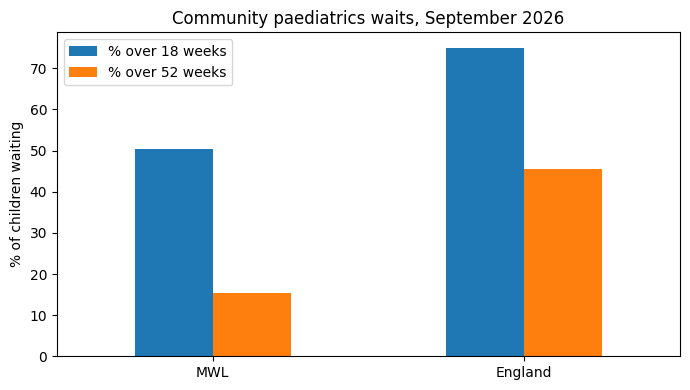

In [6]:
# community paediatrics is MWL's biggest list, so compare it with England
# same service on both sides - MWL runs a different mix of services, so overall totals aren't a fair match
service = "(CYP) Community paediatric service"

def pct(rows):
    t = rows.groupby("Band")["Waiting"].sum()
    over18 = (t["18-52w"] + t["52-104w"] + t["104w+"]) / t["Total"] * 100
    over52 = (t["52-104w"] + t["104w+"]) / t["Total"] * 100
    return round(over18, 1), round(over52, 1)

mwl_p = pct(sep[sep["Service"] == service])
eng_p = pct(eng[(eng["Month"] == "2026-27-September") & (eng["Service"] == service)])

comp = pd.DataFrame({"% over 18 weeks": [mwl_p[0], eng_p[0]],
                     "% over 52 weeks": [mwl_p[1], eng_p[1]]},
                    index=["MWL", "England"])
print(comp)

ax = comp.plot(kind="bar", figsize=(7, 4), title="Community paediatrics waits, September 2026")
ax.set_ylabel("% of children waiting")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("paediatrics_vs_england.png", dpi=150)
plt.show()

In [7]:
# data quality notes
# - Aug 2026: every MWL service reported 0, treated as a reporting error and left out
# - intermediate care has a total but no wait band breakdown
# - NHS England says this is unvalidated management information